In [4]:
# imports
# standard things
import numpy as np
import matplotlib.pyplot as plt
from glob import glob # glob is a standard python module that helps select multiple files

# thhis is new
from pyspan import Linear

In [5]:
# this is necessary. It makes jupyter use ipywidgets for matplotlib plots
%matplotlib widget 

In [6]:
# setup a list of file names. You could type it directly.
# Here we use `glob` to get all the filenames for us.
fnames = glob("s[0346]*.dat")
fnames

['s00.dat', 's30.dat', 's61.dat']

The `pyspan.Linear` (`Linear` for short) supplies widgets helpful to inspect the individual spectra, reject outliers and compute the average.

The interface displays the individual spectra and the average spectum. Furthermore, it computes the rms deviation of individual spectra from the median spectrum. Spectra with an rmsd larger than the threshold value are rejected from the average.

The easiest way to create it is to use the `Linear.from_files(fnames)` method. It is also possible to instantiate it using a wavelength array, an array containing the measured absorbances and a list of filenames. It is necessary that all spectra share the same wavelengths.

Calling the `l.plot` method generates an interface to inspect the data. It has the following elements:  
- A dropdown menu to select the file to analyze,
- A slider to select one spectrum from the repetition,
- A text box to enter a rejection threshold,
- A button to rescale the graphs.
- A button to set the threshold and calculate the mean.

The top graph indicates the following:
- The X axis is the spectrum index (ie: repetition).
- The Y axis is the RMSD from the median of each repetition.
- The blue curve is the RMSD.
- The red dashed line is the current threhold value.
- The black vertical line is a cursor of the currently displayed spectrum.

The main graph has the following elements:
- X axis is wavelength.
- Y axis is the Absorbance.
- The color curve is the currently selected spectrum. It is red if the current spectrum is rejected.
- The black line is the current average, after rejection.

In [7]:
l = Linear.from_files(fnames)
l.plot()

Once you're happy with the rejection parameters, you can access the averaged spectra.

There are two options: `l.mean_spectra` yields an array containing the average spectra for all filenames, and `l.spectra_dict` return a dict of filenames to (wl, spectrum).

In [8]:
# using `mean_spectra`
dat_array = l.mean_spectra
print("dat_array.ndim", dat_array.ndim)
print("dat_array.shape", dat_array.shape, f"== (len(l.fnames), l.wl.size)")


dat_array.ndim 2
dat_array.shape (3, 512) == (len(l.fnames), l.wl.size)


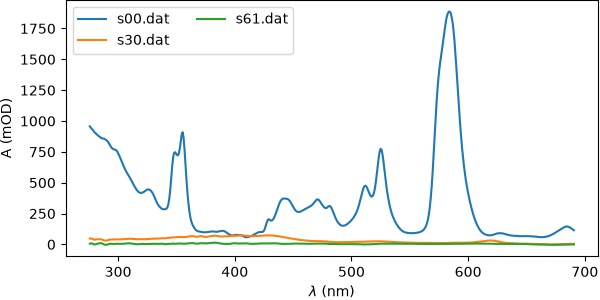

In [9]:
plt.figure(figsize=(6,3))
for i, fn in enumerate(l.fnames):
    plt.plot(l.wl, dat_array[i,:], label=fn)
plt.legend(ncols=2)
plt.xlabel(r"$\lambda$ (nm)")
plt.ylabel(r"A (mOD)")
plt.tight_layout(pad=0)

In [10]:
# using spectra_as_dict
spectra_dict = l.spectra_dict
print("keys:", *spectra_dict.keys())
print("shape of values:", list(spectra_dict.values())[0].shape)

keys: s00.dat s30.dat s61.dat
shape of values: (2, 512)


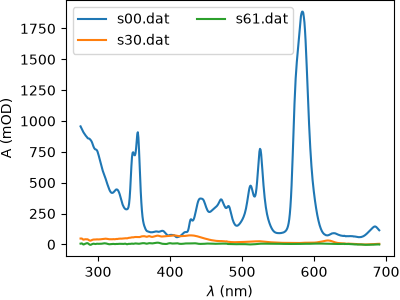

In [11]:
plt.figure(figsize=(4,3))
for fn, (wl, od) in spectra_dict.items():
    plt.plot(wl, od, label=fn)
plt.legend(ncols=2)
plt.xlabel(r"$\lambda$ (nm)")
plt.ylabel(r"A (mOD)")
plt.tight_layout(pad=0)

You can now save your data using reasonable names!